# Supplementary Figure S6 — Trace-element reproducibility

Standalone workflow for the replicate melt-inclusion trace-element panels. The shared Science Advances requirements from `Nov6_AllFigures/00_Setup` are written explicitly below so this notebook can be read and edited on its own.

In [1]:
from pathlib import Path
import string

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

# Select the folder containing the three supplemental workbooks.
DECHERT_DATA_DIRECTORY = Path('/Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/DataSheets/Updated_Oct20')
USER_DATA_DIRECTORY = Path('/replace/with/your/folder/containing/the/three/supplemental/files')
DATA_DIRECTORY = DECHERT_DATA_DIRECTORY
# DATA_DIRECTORY = USER_DATA_DIRECTORY

# Find Nov6_AllFigures from the current working directory.
PROJECT_ROOT = None
for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if candidate.name == 'Nov6_AllFigures':
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start in Nov6_AllFigures or one of its figure folders.')

FIGURE_DIRECTORY = PROJECT_ROOT / 'Figure_S06_TE_Reproducibility'
OUTPUT_DIRECTORY = FIGURE_DIRECTORY / 'Figure_S06_TE_Reproducibility_Final'
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)

WORKBOOK_PATHS = {
    'S1': Path('/Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/GP_Combined/SEIMS_SEM_Raman_LAICPMS/Combining_All_Dechert_Data/Combining_All_Dechert_Data_S1_20261110.xlsx'),
    'S2': DATA_DIRECTORY / 'Dechert_S2_Standards.xlsx',
    'S3': DATA_DIRECTORY / 'Dechert_S3_Compilations.xlsx',
}
for supplement, path in WORKBOOK_PATHS.items():
    if not path.is_file():
        raise FileNotFoundError(f'{supplement}: required supplemental file not found: {path}')

WORKBOOK_PATH = WORKBOOK_PATHS['S1']
print('Figure directory:', FIGURE_DIRECTORY)
print('Supplemental data directory:', DATA_DIRECTORY)
print('S6 source sheets: S1 / TE_MI_Replicates and MI_Hosts_Plag_Pxy')
print('Uncertainty standards: S2 / LA-ICP-MS')

Figure directory: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S06_TE_Reproducibility
Supplemental data directory: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/DataSheets/Updated_Oct20
S6 source sheets: S1 / TE_MI_Replicates and MI_Hosts_Plag_Pxy
Uncertainty standards: S2 / LA-ICP-MS


In [2]:
# Science Advances figure settings copied from Nov6_AllFigures/00_Setup.
SINGLE_COLUMN_WIDTH_IN = 3.55
DOUBLE_COLUMN_WIDTH_IN = 7.25
MAXIMUM_INTERMEDIATE_WIDTH_IN = 5.67
MAXIMUM_RECOMMENDED_HEIGHT_IN = 7.8

BASE_TEXT_SIZE_PT = 8.0
AXIS_LABEL_SIZE_PT = 8.0
TITLE_SIZE_PT = 8.0
TICK_LABEL_SIZE_PT = 8.0
LEGEND_SIZE_PT = 8.0
LEGEND_TITLE_SIZE_PT = 8.0
ANNOTATION_SIZE_PT = 8.0
MINIMUM_TEXT_SIZE_PT = 6.0
DENSE_XTICK_SIZE_PT = 6.5
DENSE_NOTE_SIZE_PT = 7.0
PANEL_LABEL_SIZE_PT = 9.0
MINIMUM_LINE_WIDTH_PT = 0.28
EXPORT_DPI = 300

PUBLICATION_FONT = 'Arial'
INSTALLED_FONT_NAMES = {entry.name for entry in font_manager.fontManager.ttflist}
if PUBLICATION_FONT not in INSTALLED_FONT_NAMES:
    raise RuntimeError('Arial is required. Install Arial and restart Python.')
PUBLICATION_FONT_PATH = font_manager.findfont(PUBLICATION_FONT, fallback_to_default=False)

mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': [PUBLICATION_FONT],
    'font.size': BASE_TEXT_SIZE_PT,
    'axes.labelsize': AXIS_LABEL_SIZE_PT,
    'axes.titlesize': TITLE_SIZE_PT,
    'xtick.labelsize': TICK_LABEL_SIZE_PT,
    'ytick.labelsize': TICK_LABEL_SIZE_PT,
    'legend.fontsize': LEGEND_SIZE_PT,
    'legend.title_fontsize': LEGEND_TITLE_SIZE_PT,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.grid': False,
    'axes.spines.top': True,
    'axes.spines.right': True,
    'axes.linewidth': 0.5,
    'lines.linewidth': 0.75,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'xtick.minor.visible': False,
    'ytick.minor.visible': False,
    'savefig.dpi': EXPORT_DPI,
    'savefig.facecolor': 'white',
    'savefig.transparent': False,
    'mathtext.fontset': 'custom',
    'mathtext.rm': PUBLICATION_FONT,
    'mathtext.it': f'{PUBLICATION_FONT}:italic',
    'mathtext.bf': f'{PUBLICATION_FONT}:bold',
    'mathtext.bfit': f'{PUBLICATION_FONT}:bold:italic',
    'mathtext.fallback': 'stix',
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'svg.fonttype': 'none',
})

print('Publication font:', PUBLICATION_FONT_PATH)
print('Figure width:', DOUBLE_COLUMN_WIDTH_IN, 'in')
print('Maximum figure height:', MAXIMUM_RECOMMENDED_HEIGHT_IN, 'in')

Publication font: /System/Library/Fonts/Supplemental/Arial.ttf
Figure width: 7.25 in
Maximum figure height: 7.8 in


## Figure S6-specific data selection

The shared publication setup is complete above. Everything below applies only to the trace-element reproducibility figure. The filters and spot-level provenance are unchanged from the previous S6 notebook.

In [3]:
PHASE_STYLES = {
    'plag': {'label': 'Plagioclase-hosted', 'marker': 'o'},
    'pxy': {'label': 'Pyroxene-hosted', 'marker': 's'},
}
MARKER_SPANS_PT = {'plag': 6.0, 'pxy': 6.0}

te_elements = {
    'Rb': '85Rb', 'Sr': '88Sr', 'Y': '89Y', 'Zr': '90Zr', 'Nb': '93Nb',
    'Ba': '137Ba', 'La': '139La', 'Ce': '140Ce', 'Nd': '146Nd',
    'Sm': '147Sm', 'Eu': '153Eu', 'Gd': '157Gd', 'Tb': '159Tb',
    'Dy': '163Dy', 'Yb': '171Yb', 'Th': '232Th', 'U': '238U',
    'Hf': '178Hf', 'Ho': '165Ho', 'Lu': '175Lu',
}

replicates = pd.read_excel(WORKBOOK_PATH, sheet_name='TE_MI_Replicates')
combined = pd.read_excel(
    WORKBOOK_PATH,
    sheet_name='MI_Hosts_Plag_Pxy',
    usecols=['base_name', 'mineral_phase', 'Discard_SIMS'],
)

required_replicate_columns = {'base_name', 'mineral_phase'}
missing_required = sorted(required_replicate_columns.difference(replicates.columns))
if missing_required:
    raise KeyError(f'TE_MI_Replicates is missing required columns: {missing_required}')
if 'Discard_SIMS' not in combined.columns:
    raise KeyError('MI_Hosts_Plag_Pxy is missing required column: Discard_SIMS')
if combined['base_name'].duplicated().any():
    raise ValueError('MI_Hosts_Plag_Pxy contains duplicate base_name values; the eligibility merge is unsafe.')

data = replicates.merge(
    combined[['base_name', 'Discard_SIMS']],
    on='base_name',
    how='left',
    validate='one_to_one',
)

phase_normalized = data['mineral_phase'].astype('string').str.strip().str.lower()
discard_sims = data['Discard_SIMS'].astype('string').str.strip().str.lower().eq('yes').fillna(False)
is_mi_name = data['base_name'].astype('string').str.contains('(?:^|_)MI\\d*', case=False, regex=True, na=False)
excluded_material = data['base_name'].astype('string').str.contains(
    'matrix|(?:^|_)mtx(?:_|$)|dacite|vein|whole[ _-]?rock|kuehn',
    case=False,
    regex=True,
    na=False,
)
valid_phase = phase_normalized.isin(PHASE_STYLES)
row_eligibility = ~discard_sims & is_mi_name & ~excluded_material & valid_phase

print('Rows loaded:', len(data))
print('Rows eligible before individual TE-spot filtering:', int(row_eligibility.sum()))

Rows loaded: 212
Rows eligible before individual TE-spot filtering: 186


In [4]:
# Convert the three possible TE spots per melt inclusion into one explicit table.
# Cautious/skeptical flags were intentionally removed from the current S1 data.
NON_DISCARD_TOKENS = {'', 'no', 'n', 'false', '0', 'nan', 'none', '<na>'}

available_elements = []
element_spot_columns = {}
for element, isotope in te_elements.items():
    columns = [f'{isotope}_TE{spot}_MI' for spot in (1, 2, 3)]
    columns = [column for column in columns if column in data.columns]
    if columns:
        available_elements.append(element)
        element_spot_columns[element] = columns

records = []
discarded_spot_rows = []
for row_index, row in data.loc[row_eligibility].iterrows():
    phase = str(row['mineral_phase']).strip().lower()

    for spot in (1, 2, 3):
        discard_column = f'Discard_TE{spot}_MI'
        discard_value = row.get(discard_column, np.nan)
        if pd.isna(discard_value):
            spot_discarded = False
        else:
            spot_discarded = str(discard_value).strip().casefold() not in NON_DISCARD_TOKENS

        if spot_discarded:
            discarded_spot_rows.append({
                'source_row': row_index,
                'base_name': row['base_name'],
                'spot': spot,
                'discard_value': discard_value,
            })
            continue

        for element in available_elements:
            isotope = te_elements[element]
            value_column = f'{isotope}_TE{spot}_MI'
            if value_column not in data.columns:
                continue

            value = pd.to_numeric(pd.Series([row[value_column]]), errors='coerce').iloc[0]
            if pd.isna(value) or not np.isfinite(value):
                continue

            records.append({
                'source_row': row_index,
                'base_name': str(row['base_name']).strip(),
                'mineral_phase': phase,
                'spot': spot,
                'element': element,
                'isotope_column': value_column,
                'value_ppm': float(value),
            })

tidy = pd.DataFrame.from_records(records)
if tidy.empty:
    raise ValueError('No numeric MI trace-element records remained after filtering.')

repeat_counts_all = (
    tidy.groupby(['element', 'mineral_phase', 'base_name'], as_index=False)
    .size()
    .rename(columns={'size': 'retained_analysis_count'})
)
repeat_keys = repeat_counts_all.loc[
    repeat_counts_all['retained_analysis_count'] > 1,
    ['element', 'mineral_phase', 'base_name'],
]
plot_data = tidy.merge(
    repeat_keys,
    on=['element', 'mineral_phase', 'base_name'],
    how='inner',
    validate='many_to_one',
)

qualifying_elements = [element for element in available_elements if element in set(plot_data['element'])]
skipped_elements = [element for element in te_elements if element not in qualifying_elements]
repeated_mis = sorted(plot_data['base_name'].unique(), key=str.casefold)

print('Individual discarded TE spots excluded:', len(discarded_spot_rows))
print('Numeric TE values before repeat requirement:', len(tidy))
print('Repeated melt inclusions plotted:', len(repeated_mis))
print('Elements plotted:', qualifying_elements)
print('Elements skipped:', skipped_elements)
print('Replicate points plotted:', len(plot_data))

Individual discarded TE spots excluded: 1
Numeric TE values before repeat requirement: 2185
Repeated melt inclusions plotted: 24
Elements plotted: ['Rb', 'Sr', 'Y', 'Zr', 'Nb', 'Ba', 'La', 'Ce', 'Nd', 'Sm', 'Eu', 'Gd', 'Tb', 'Dy', 'Yb', 'Th', 'U', 'Hf', 'Ho']
Elements skipped: ['Lu']
Replicate points plotted: 988


In [5]:
# Assign one deterministic color to each repeatedly analyzed melt inclusion.
palette_colors = []
for cmap_name in ('tab20', 'tab20b', 'tab20c'):
    cmap = mpl.colormaps[cmap_name]
    palette_colors.extend([mpl.colors.to_hex(cmap(i)) for i in np.linspace(0, 1, cmap.N)])
mi_colors = {
    base_name: palette_colors[index % len(palette_colors)]
    for index, base_name in enumerate(repeated_mis)
}

# Sort without a hidden sorting function.
point_audit = plot_data.copy()
point_audit['_element_sort'] = point_audit['element'].astype(str).str.casefold()
point_audit['_phase_sort'] = point_audit['mineral_phase'].astype(str).str.casefold()
point_audit['_name_sort'] = point_audit['base_name'].astype(str).str.casefold()
point_audit = point_audit.sort_values(
    ['_element_sort', '_phase_sort', '_name_sort', 'spot'],
    kind='stable',
).drop(columns=['_element_sort', '_phase_sort', '_name_sort']).reset_index(drop=True)

count_audit = (
    point_audit.groupby(['element', 'mineral_phase', 'base_name'], as_index=False)
    .agg(
        retained_analysis_count=('value_ppm', 'size'),
        minimum_ppm=('value_ppm', 'min'),
        maximum_ppm=('value_ppm', 'max'),
    )
)

element_audit_rows = []
for element, isotope in te_elements.items():
    subset = point_audit.loc[point_audit['element'].eq(element)]
    element_audit_rows.append({
        'element': element,
        'isotope': isotope,
        'available_source_columns': '|'.join(element_spot_columns.get(element, [])),
        'qualifies_for_plotting': element in qualifying_elements,
        'plagioclase_repeated_MI_count': subset.loc[subset['mineral_phase'].eq('plag'), 'base_name'].nunique(),
        'pyroxene_repeated_MI_count': subset.loc[subset['mineral_phase'].eq('pxy'), 'base_name'].nunique(),
        'plotted_point_count': len(subset),
    })
element_audit = pd.DataFrame(element_audit_rows)
discarded_spot_audit = pd.DataFrame(discarded_spot_rows)

display(element_audit)
display(count_audit.head(12))

,element,isotope,available_source_columns,qualifies_for_plotting,plagioclase_repeated_MI_count,pyroxene_repeated_MI_count,plotted_point_count
0,Rb,85Rb,85Rb_TE1_MI|85Rb_TE2_MI|85Rb_TE3_MI,True,11,13,52
1,Sr,88Sr,88Sr_TE1_MI|88Sr_TE2_MI|88Sr_TE3_MI,True,11,13,52
2,Y,89Y,89Y_TE1_MI|89Y_TE2_MI|89Y_TE3_MI,True,11,13,52
3,Zr,90Zr,90Zr_TE1_MI|90Zr_TE2_MI|90Zr_TE3_MI,True,11,13,52
4,Nb,93Nb,93Nb_TE1_MI|93Nb_TE2_MI|93Nb_TE3_MI,True,11,13,52
5,Ba,137Ba,137Ba_TE1_MI|137Ba_TE2_MI|137Ba_TE3_MI,True,11,13,52
6,La,139La,139La_TE1_MI|139La_TE2_MI|139La_TE3_MI,True,11,13,52
7,Ce,140Ce,140Ce_TE1_MI|140Ce_TE2_MI|140Ce_TE3_MI,True,11,13,52
8,Nd,146Nd,146Nd_TE1_MI|146Nd_TE2_MI|146Nd_TE3_MI,True,11,13,52
9,Sm,147Sm,147Sm_TE1_MI|147Sm_TE2_MI|147Sm_TE3_MI,True,11,13,52


,element,mineral_phase,base_name,retained_analysis_count,minimum_ppm,maximum_ppm
0,Ba,plag,74A_C10_MI1,3,784.064037,826.178805
1,Ba,plag,74A_C3_MI1,2,796.841537,811.491277
2,Ba,plag,74A_C8_MI1,2,748.212891,760.379953
3,Ba,plag,74D_C12_MI1,2,795.661905,812.031523
4,Ba,plag,75_C12_MI1,2,705.319045,721.800864
5,Ba,plag,75_C2_MI3,2,737.793844,773.691568
6,Ba,plag,75_C4_MI1,2,731.514426,759.672961
7,Ba,plag,75_C7_MI3,2,707.747770,723.671012
8,Ba,plag,75_C8_MI1,2,851.676887,859.198653
9,Ba,plag,76A_C4_MI1,3,722.564363,759.820455


## Per-measurement uncertainties

The manuscript figure uses each original LADR-reported uncertainty. The three LADR workbooks are private processing exports and are not included with the public supplemental data. The optional `secondary_reproducibility` mode uses the public S2 session-specific secondary-standard relative 1SD instead.

In [6]:
# Manuscript default: individual outputted LADR uncertainties (external files required).
# Public alternative: S2 session-specific secondary-standard relative reproducibility.
UNCERTAINTY_MODE = 'LADR'  # 'LADR' or 'secondary_reproducibility'
Dechert_LADR_directory = Path('/Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/GP_LAICPMS/MIs+Hosts/Dechert-Wieser_GP-MI_Final/raw_processed_data')
User_LADR_directory = Path('/replace/with/folder/containing/original/LADR/exports')
LADR_DIRECTORY = Dechert_LADR_directory
# LADR_DIRECTORY = User_LADR_directory
# Session-specific MPI-DING secondary glasses; no common standard spans all sessions.
SECONDARY_STANDARD_BY_SESSION = {
    '20260615': 'T1-G',
    '20260618': 'ATHO',
    '20260622': 'ATHO',
}


# Read individual melt-inclusion standard analyses from the revised S2 layout.
# The date parser accepts Excel datetimes and numeric Excel serial dates.
def parse_excel_date(value):
    if pd.isna(value):
        return pd.NaT
    if isinstance(value, (int, float, np.integer, np.floating)):
        return pd.to_datetime(value, unit='D', origin='1899-12-30', errors='coerce')
    return pd.to_datetime(value, errors='coerce')


def read_melt_inclusion_standard_analyses(path, isotopes):
    raw = pd.read_excel(path, sheet_name='LA-ICP-MS', header=None)
    row_labels = raw.iloc[:, 0].astype('string').str.strip().str.upper()
    section_starts = raw.index[row_labels.eq('MELT INCLUSIONS')].tolist()
    if len(section_starts) != 1:
        raise ValueError(f'Expected one MELT INCLUSIONS section; found {len(section_starts)}.')
    section_start = section_starts[0]
    later_sections = raw.index[
        raw.index.to_series().gt(section_start)
        & row_labels.isin(['PLAGIOCLASE', 'ORTHOPYROXENE'])
    ].tolist()
    section_end = min(later_sections) if later_sections else len(raw)
    header_rows = [
        row_index for row_index in range(section_start + 1, section_end)
        if str(raw.iat[row_index, 0]).strip().casefold() == 'sample'
        and str(raw.iat[row_index, 1]).strip().casefold() == 'date'
        and str(raw.iat[row_index, 2]).strip().casefold() == 'type'
    ]
    if not header_rows:
        raise ValueError('No Sample/date/type header was found in the MELT INCLUSIONS section.')

    blocks = []
    for header_position, header_row in enumerate(header_rows):
        block_end = header_rows[header_position + 1] if header_position + 1 < len(header_rows) else section_end
        headers = [str(value).strip() if pd.notna(value) else '' for value in raw.iloc[header_row]]
        requested = ['Sample', 'date', 'type', *isotopes]
        column_positions = {name: headers.index(name) for name in requested if name in headers}
        missing_base_columns = [name for name in ['Sample', 'date', 'type'] if name not in column_positions]
        if missing_base_columns:
            raise KeyError(f'Missing standard-analysis columns: {missing_base_columns}')
        block = raw.iloc[header_row + 1:block_end, list(column_positions.values())].copy()
        block.columns = list(column_positions)
        blocks.append(block)

    analyses = pd.concat(blocks, ignore_index=True)
    analyses['date'] = analyses['date'].map(parse_excel_date)
    analyses['session'] = analyses['date'].dt.strftime('%Y%m%d')
    analyses['type'] = analyses['type'].astype('string').str.strip().str.casefold()
    analyses['standard'] = (
        analyses['Sample'].astype('string')
        .str.replace(r'\s*-\s*\d+\s*$', '', regex=True)
        .str.strip().str.upper()
    )
    return analyses
# Verified provenance: all 119 MI spots matched uniquely to original LADR
# concentrations using nine isotopes (rtol=2e-7, atol=1e-7 ppm).
# Mapping preserves the original analysis labels despite subsequent naming fixes
# and chronological TE1/TE2/TE3 renumbering. No external files needed in S2 mode.
LADR_SPOT_PROVENANCE = {'74A_C10_MI1|1': ['20260615_sasm_GP-MIs-GSD-Si_DATA_reprocessed.xlsx', 5, '74A_C10_MI1 - 1'], '74A_C10_MI1|2': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 11, '74A_C10_MI1 - 1'], '74A_C10_MI1|3': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 9, '74A_C10_MI1 - 1'], '74A_C10_MI2|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 12, '74A_C10_MI2 - 1'], '74A_C13_MI2|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 14, '74A_C13_MI2 - 1'], '74A_C15_MI1|1': ['20260615_sasm_GP-MIs-GSD-Si_DATA_reprocessed.xlsx', 7, '74A_C15_MI1 - 1'], '74A_C16_MI1|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 10, '74A_C16_MI1 - 1'], '74A_C18_MI1|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 11, '74A_C18_MI1 - 1'], '74A_C18_MI2|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 12, '74A_C18_MI2 - 1'], '74A_C19_MI2|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 16, '74A_C19_MI2 - 1'], '74A_C19_MI4|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 13, '74A_C19_MI4 - 1'], '74A_C1_MI1|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 6, '74A_C1_MI1 - 1'], '74A_C20_MI1|1': ['20260615_sasm_GP-MIs-GSD-Si_DATA_reprocessed.xlsx', 9, '74A_C20_MI1 - 1'], '74A_C20_MI1|2': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 17, '74A_C20_MI1 - 1'], '74A_C20_MI4|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 14, '74A_C20_MI4 - 1'], '74A_C20_MI5|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 15, '74A_C20_MI5 - 1'], '74A_C21_MI1|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 19, '74A_C21_MI1 - 1'], '74A_C22_MI1|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 20, '74A_C22_MI1 - 1'], '74A_C22_MI1|2': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 16, '74A_C22_MI1 - 1'], '74A_C22_MI3|1': ['20260615_sasm_GP-MIs-GSD-Si_DATA_reprocessed.xlsx', 11, '74A_C22_MI1 - 1'], '74A_C22_MI3|2': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 30, '74A_C22_MI3 - 1'], '74A_C22_MI3|3': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 25, '74A_C22_MI3 - 1'], '74A_C23_MI3|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 31, '74A_C23_MI3 - 1'], '74A_C24_MI1|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 33, '74A_C24_MI1 - 1'], '74A_C24_MI1|2': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 26, '74A_C24_MI1 - 1'], '74A_C24_MI2|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 34, '74A_C24_MI2 - 1'], '74A_C26_MI1|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 35, '74A_C26_MI1 - 1'], '74A_C26_MI2|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 36, '74A_C26_MI2 - 1'], '74A_C27_MI1|1': ['20260615_sasm_GP-MIs-GSD-Si_DATA_reprocessed.xlsx', 13, '74A_C27_MI1 - 1'], '74A_C27_MI1|2': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 27, '74A_C27_MI1 - 1'], '74A_C27_MI2|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 28, '74A_C27_MI2 - 1'], '74A_C27_MI4|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 30, '74A_C27_MI4 - 1'], '74A_C29_MI1|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 31, '74A_C29_MI1 - 1'], '74A_C3_MI1|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 7, '74A_C3_MI1 - 1'], '74A_C3_MI1|2': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 6, '74A_C3_MI1 - 1'], '74A_C5_MI1|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 8, '74A_C5_MI1 - 1'], '74A_C8_MI1|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 9, '74A_C8_MI1 - 1'], '74A_C8_MI1|2': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 7, '74A_C8_MI1 - 1'], '74A_C9_MI1|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 8, '74A_C9_MI1 - 1'], '74D_C12_MI1|1': ['20260615_sasm_GP-MIs-GSD-Si_DATA_reprocessed.xlsx', 15, '74D_C12-MI1 - 1'], '74D_C12_MI1|2': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 38, '74D_C12_MI1 - 1'], '74D_C12_MI2|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 39, '74D_C12_MI2 - 1'], '74D_C15_MI2|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 40, '74D_C15_MI2 - 1'], '74D_C31_MI1|1': ['20260615_sasm_GP-MIs-GSD-Si_DATA_reprocessed.xlsx', 17, '74D_C31-MI1 - 1'], '74D_C33_MI1|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 32, '74D_C33_MI1 - 1'], '74D_C35_MI1|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 33, '74D_C35_MI1 - 1'], '74D_C38_MI1|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 44, '74D_C38_MI1 - 1'], '74D_C40_MI1|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 45, '74D_C40_MI1 - 1'], '74D_C42_MI1|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 47, '74D_C42_MI1 - 1'], '74D_C43_MI1|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 34, '74D_C43_MI1 - 1'], '74D_C45_MI1|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 36, '74D_C45_MI1 - 1'], '74D_C51_MI1|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 44, '74D_C51_MI1 - 1'], '74D_C8_MI1|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 37, '74D_C8_MI1 - 1'], '75_C11_MI1|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 63, '75_C11_MI1 - 1'], '75_C12_MI1|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 64, '75_C12_MI1 - 1'], '75_C12_MI1|2': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 65, '75_C12_MI1 - 2'], '75_C18_MI2|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 64, '75_C18_MI2 - 1'], '75_C18_MI2|2': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 66, '75_C18_MI2 - 1'], '75_C19_MI2|1': ['20260615_sasm_GP-MIs-GSD-Si_DATA_reprocessed.xlsx', 27, '75_C19-MI2 - 1'], '75_C19_MI2|2': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 65, '75_C19_MI2 - 1'], '75_C19_MI2|3': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 67, '75_C19_MI2 - 1'], '75_C19_MI3|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 66, '75_C19_MI3 - 1'], '75_C19_MI3|2': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 68, '75_C19_MI3 - 1'], '75_C19_MI4|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 69, '75_C19_MI4 - 1'], '75_C21_MI1|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 77, '75_C21_MI1 - 1'], '75_C23_MI2|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 70, '75_C23_MI2 - 1'], '75_C24_MI1|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 77, '75_C24_MI1 - 1'], '75_C2_MI3|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 57, '75_C2_MI3 - 1'], '75_C2_MI3|2': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 48, '75_C2_MI3 - 1'], '75_C33_MI1|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 54, '75_C33_MI1 - 1'], '75_C34_MI1|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 55, '75_C34_MI1 - 1'], '75_C34_MI2|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 56, '75_C34_MI12 - 1'], '75_C34_MI2|2': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 45, '75_C34_MI2 - 1'], '75_C35_MI1|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 46, '75_C35_MI2 - 1'], '75_C36_MI1|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 47, '75_C36_MI2 - 1'], '75_C4_MI1|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 58, '75_C4_MI1 - 1'], '75_C4_MI1|2': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 59, '75_C4_MI1 - 2'], '75_C5_MI1|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 50, '75_C5_MI1 - 1'], '75_C7_MI2|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 62, '75_C7_MI2 - 1'], '75_C7_MI3|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 63, '75_C7_MI3 - 1'], '75_C7_MI3|2': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 51, '75_C7_MI3 - 1'], '75_C8_MI1|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 52, '75_C8_MI1 - 1'], '75_C8_MI1|2': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 53, '75_C8_MI1 - 2'], '75_C9_MI2|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 54, '75_C9_MI2 - 1'], '76A_C11_MI2|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 83, '76A_C11_MI2 - 1'], '76A_C14_MI2|1': ['20260615_sasm_GP-MIs-GSD-Si_DATA_reprocessed.xlsx', 33, '76A_C14-MI2 - 1'], '76A_C14_MI3|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 84, '76A_C14_MI3 - 1'], '76A_C14_MI4|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 85, '76A_C14_MI4 - 1'], '76A_C16_MI2|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 87, '76A_C16_MI2 - 1'], '76A_C18_MI2|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 86, '76A_C18_MI2 - 2'], '76A_C18_MI3|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 88, '76A_C18_MI3 - 1'], '76A_C20_MI3|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 88, '76A_C20_MI2 - 1'], '76A_C21_MI1|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 89, '76A_C21_MI1 - 1'], '76A_C21_MI1|2': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 97, '76A_C21_M! - 1'], '76A_C21_MI2|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 90, '76A_C21_MI1 - 2'], '76A_C22_MI2|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 91, '76A_C22_MI2 - 1'], '76A_C23_MI2|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 98, '76A_C23_MI2 - 1'], '76A_C26_MI2|1': ['20260615_sasm_GP-MIs-GSD-Si_DATA_reprocessed.xlsx', 35, '76A_C26-MI2 - 1'], '76A_C26_MI3|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 99, '76A_C26_MI3 - 1'], '76A_C27_MI2|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 100, '76A_C27_MI2 - 1'], '76A_C28_MI2|1': ['20260615_sasm_GP-MIs-GSD-Si_DATA_reprocessed.xlsx', 37, '76A_C28-MI2 - 1'], '76A_C28_MI2|2': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 101, '76A_C28_MI2 - 1'], '76A_C28_MI3|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 102, '76A_C28_MI3 - 1'], '76A_C28_MI4|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 103, '76A_C28_MI4 - 1'], '76A_C28_MI4|2': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 104, '76A_C28_MI4 - 2'], '76A_C29_MI2|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 105, '76A_C29_MI2 - 1'], '76A_C2_MI2|1': ['20260615_sasm_GP-MIs-GSD-Si_DATA_reprocessed.xlsx', 29, '76A_C2-MI2 - 1'], '76A_C2_MI3|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 79, '76A_C2_MI3 - 1'], '76A_C31_MI2|1': ['20260615_sasm_GP-MIs-GSD-Si_DATA_reprocessed.xlsx', 39, '76A_C31-MI2 - 1'], '76A_C31_MI2|2': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 106, '76A_C31_MI2 - 1'], '76A_C32_MI2|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 107, '76A_C32_MI2 - 1'], '76A_C4_MI1|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 80, '76A_C4_MI1 - 1'], '76A_C4_MI1|2': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 79, '76A_C4_MI1 - 1'], '76A_C4_MI1|3': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 80, '76A_C4_MI1 - 2'], '76A_C4_MI2|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 81, '76A_C4_MI2 - 1'], '76A_C4_MI2|2': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 81, '76A_C4_MI2 - 1'], '76A_C7_MI2|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 82, '76A_C7_MI2 - 1'], '76A_C7_MI3|1': ['20260618_sasm_GP-MI_GSE-Al_DATA.xlsx', 83, '76A_C7_MI3 - 1'], '76A_C8_MI2|1': ['20260622_sasm_GP-MI_GSE-Al_DATA.xlsx', 82, '76A_C8_MI2 - 1']}
assert UNCERTAINTY_MODE in {'LADR', 'secondary_reproducibility'}
standard_analyses = read_melt_inclusion_standard_analyses(
    WORKBOOK_PATHS['S2'], sorted(set(te_elements.values()))
)
secondary_reproducibility_rows = []
secondary_relative_1sigma = {}
for session, standard in SECONDARY_STANDARD_BY_SESSION.items():
    session_rows = standard_analyses.loc[
        standard_analyses['session'].eq(session)
        & standard_analyses['type'].eq('secondary')
        & standard_analyses['standard'].eq(standard)
    ]
    for isotope in sorted(set(te_elements.values())):
        if isotope not in session_rows.columns:
            continue
        values = pd.to_numeric(session_rows[isotope], errors='coerce').dropna()
        if len(values) < 2:
            continue
        measured_mean = values.mean()
        sample_sd = values.std(ddof=1)
        if not np.isfinite(measured_mean) or measured_mean == 0:
            raise ValueError(f'{session} {standard} {isotope}: invalid measured mean.')
        relative_1sigma = sample_sd / abs(measured_mean)
        secondary_relative_1sigma[(session, isotope)] = relative_1sigma
        secondary_reproducibility_rows.append({
            'session': session,
            'standard': standard,
            'isotope': isotope,
            'secondary_analysis_count': len(values),
            'measured_mean_ppm': measured_mean,
            'sample_sd_ppm': sample_sd,
            'relative_1sigma': relative_1sigma,
        })
secondary_reproducibility_audit = pd.DataFrame(secondary_reproducibility_rows)
for session in SECONDARY_STANDARD_BY_SESSION:
    if (session, '178Hf') not in secondary_relative_1sigma:
        raise ValueError(f'{session}: revised S2 data did not yield a 178Hf uncertainty.')
ladr_cache = {}
uncertainty_rows = []
for (base_name, spot), group in point_audit.groupby(['base_name', 'spot'], sort=False):
    key = f'{base_name}|{int(spot)}'
    if key not in LADR_SPOT_PROVENANCE:
        raise ValueError(f'No verified uncertainty provenance for {key}; inspect source changes.')
    filename, source_index, source_sample = LADR_SPOT_PROVENANCE[key]
    session = filename[:8]
    if UNCERTAINTY_MODE == 'LADR':
        path = LADR_DIRECTORY / filename
        if not path.is_file():
            raise FileNotFoundError(f'{path}: original LADR exports are not included in S1–S3. Set LADR_DIRECTORY or select secondary_reproducibility.')
        if filename not in ladr_cache:
            info = pd.read_excel(path, sheet_name='Information', header=None)
            settings = dict(zip(info.iloc[:, 0], info.iloc[:, 1]))
            assert settings['Reported Uncertainty'] == '1 x Unc.'
            assert settings['Reported Uncertainty Level'] == 'Full Within-Lab Analytical Precision With Secondary Standard Correction'
            concentration = pd.read_excel(path, sheet_name='Concentration_PPM')
            uncertainty = pd.read_excel(path, sheet_name='Uncertainty_PPM')
            assert concentration['Analysis'].equals(uncertainty['Analysis'])
            ladr_cache[filename] = (concentration, uncertainty)
        concentration, uncertainty = ladr_cache[filename]
        assert str(concentration.iloc[source_index]['Sample']) == source_sample
    else:
        standard = SECONDARY_STANDARD_BY_SESSION[session]
    for index, record in group.iterrows():
        isotope = te_elements[record['element']]
        if UNCERTAINTY_MODE == 'LADR':
            original_value = float(concentration.iloc[source_index][isotope])
            assert np.isclose(original_value, record['value_ppm'], rtol=2e-7, atol=1e-7), (key, isotope)
            error = float(uncertainty.iloc[source_index][isotope])
            source_label = 'LADR: 1 × reported uncertainty'
        else:
            relative_1sigma = secondary_relative_1sigma.get((session, isotope))
            if relative_1sigma is None:
                uncertainty_rows.append({'point_index': index, 'uncertainty_ppm': np.nan, 'uncertainty_source': f'{session}: no matching {isotope} in S2; point shown without bar', 'session': session})
                continue
            error = abs(record['value_ppm']) * relative_1sigma
            source_label = f'{session}: {standard}, relative 1SD scaled to MI concentration'
        if not np.isfinite(error) or error < 0:
            raise ValueError(f'Invalid uncertainty for {key}, {isotope}.')
        uncertainty_rows.append({'point_index': index, 'uncertainty_ppm': error, 'uncertainty_source': source_label, 'session': session})
uncertainty_audit = pd.DataFrame(uncertainty_rows).set_index('point_index')
point_audit = point_audit.join(uncertainty_audit, validate='one_to_one')
if UNCERTAINTY_MODE == 'LADR':
    assert point_audit['uncertainty_ppm'].notna().all()
UNCERTAINTY_LABEL = ('LADR: ±1 × reported uncertainty' if UNCERTAINTY_MODE == 'LADR'
                     else 'S2 secondary-standard relative ±1SD; Lu: no matching S2 uncertainty')
print(UNCERTAINTY_LABEL)
print(f'Uncertainty bars: {len(point_audit)}; concentrations and filters unchanged.')
display(point_audit.groupby(['session', 'uncertainty_source']).size().rename('points').to_frame())

LADR: ±1 × reported uncertainty
Uncertainty bars: 988; concentrations and filters unchanged.


,,points
session,uncertainty_source,
20260615,LADR: 1 × reported uncertainty,152
20260618,LADR: 1 × reported uncertainty,361
20260622,LADR: 1 × reported uncertainty,475


## Paginated Figure S6

Each page contains four elements. Plagioclase-hosted inclusions are in the left column and pyroxene-hosted inclusions are in the right column. Every panel has an independent concentration axis.

Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S06_TE_Reproducibility/Figure_S06_TE_Reproducibility_Final/Figure_S06_TE_Reproducibility_page_01.pdf
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S06_TE_Reproducibility/Figure_S06_TE_Reproducibility_Final/Figure_S06_TE_Reproducibility_page_01.png


Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S06_TE_Reproducibility/Figure_S06_TE_Reproducibility_Final/Figure_S06_TE_Reproducibility_page_01.svg


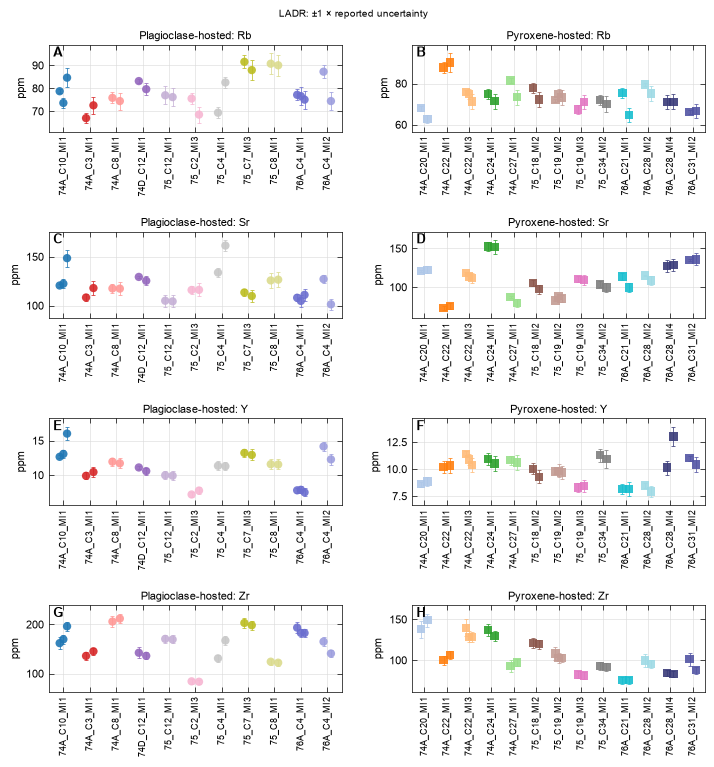

Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S06_TE_Reproducibility/Figure_S06_TE_Reproducibility_Final/Figure_S06_TE_Reproducibility_page_02.pdf
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S06_TE_Reproducibility/Figure_S06_TE_Reproducibility_Final/Figure_S06_TE_Reproducibility_page_02.png


Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S06_TE_Reproducibility/Figure_S06_TE_Reproducibility_Final/Figure_S06_TE_Reproducibility_page_02.svg


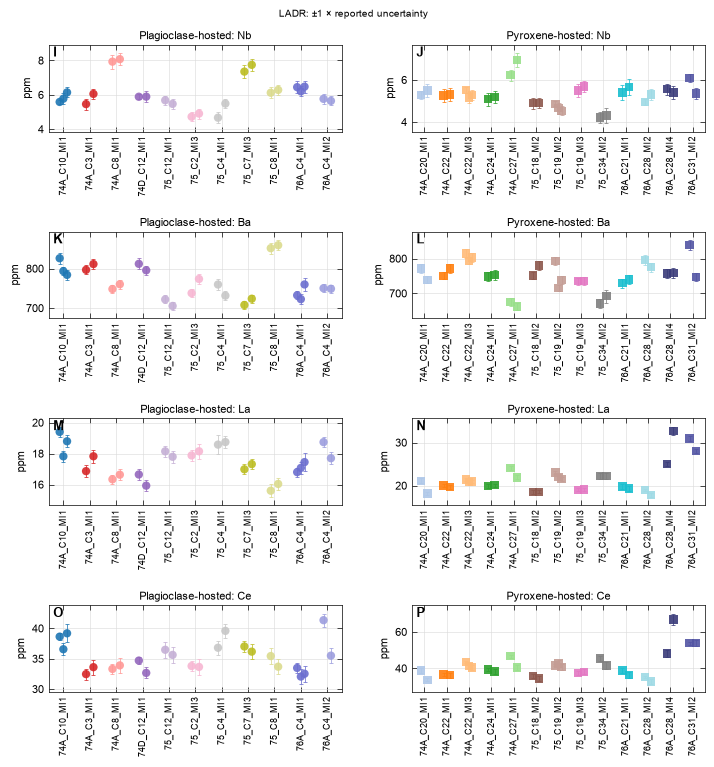

Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S06_TE_Reproducibility/Figure_S06_TE_Reproducibility_Final/Figure_S06_TE_Reproducibility_page_03.pdf
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S06_TE_Reproducibility/Figure_S06_TE_Reproducibility_Final/Figure_S06_TE_Reproducibility_page_03.png


Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S06_TE_Reproducibility/Figure_S06_TE_Reproducibility_Final/Figure_S06_TE_Reproducibility_page_03.svg


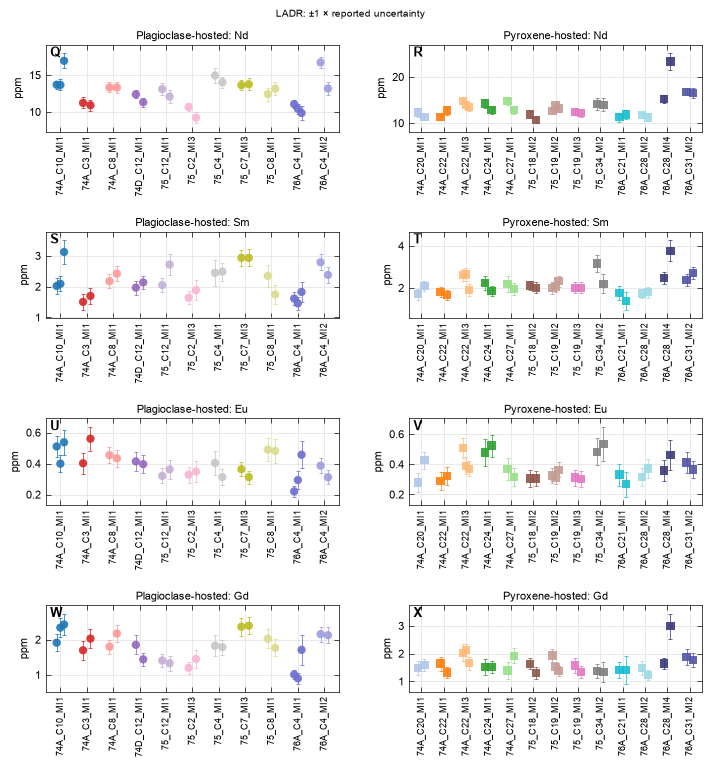

Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S06_TE_Reproducibility/Figure_S06_TE_Reproducibility_Final/Figure_S06_TE_Reproducibility_page_04.pdf
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S06_TE_Reproducibility/Figure_S06_TE_Reproducibility_Final/Figure_S06_TE_Reproducibility_page_04.png


Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S06_TE_Reproducibility/Figure_S06_TE_Reproducibility_Final/Figure_S06_TE_Reproducibility_page_04.svg


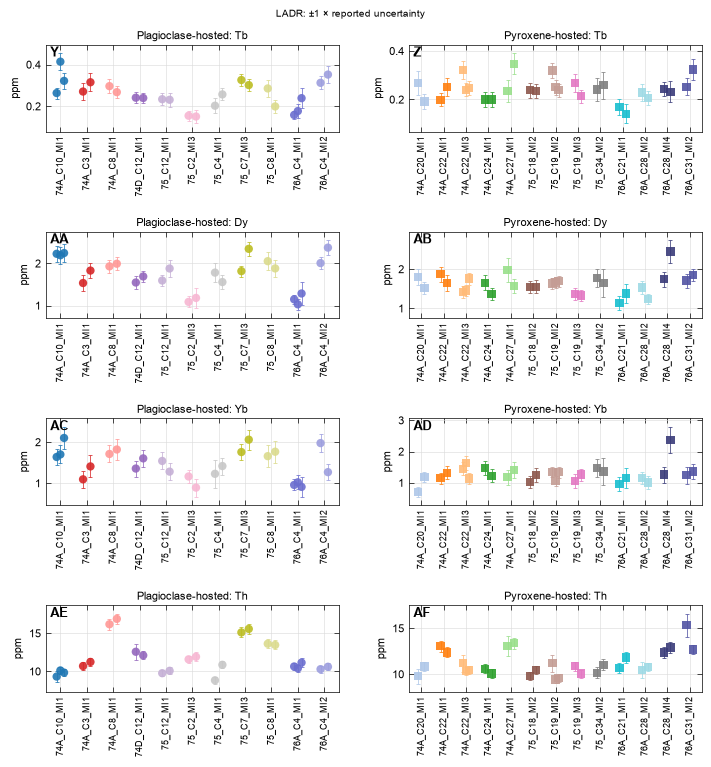

Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S06_TE_Reproducibility/Figure_S06_TE_Reproducibility_Final/Figure_S06_TE_Reproducibility_page_05.pdf
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S06_TE_Reproducibility/Figure_S06_TE_Reproducibility_Final/Figure_S06_TE_Reproducibility_page_05.png
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S06_TE_Reproducibility/Figure_S06_TE_Reproducibility_Final/Figure_S06_TE_Reproducibility_page_05.svg


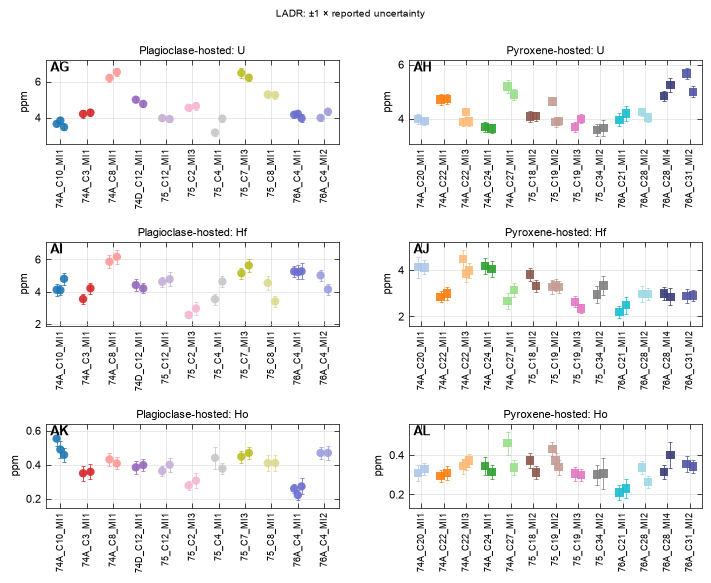

,page,elements,width_inches,height_inches,pdf_path,png_path,svg_path
0,1,Rb|Sr|Y|Zr,7.25,7.8,/Users/annikadechert/Library/Mobile Documents/...,/Users/annikadechert/Library/Mobile Documents/...,/Users/annikadechert/Library/Mobile Documents/...
1,2,Nb|Ba|La|Ce,7.25,7.8,/Users/annikadechert/Library/Mobile Documents/...,/Users/annikadechert/Library/Mobile Documents/...,/Users/annikadechert/Library/Mobile Documents/...
2,3,Nd|Sm|Eu|Gd,7.25,7.8,/Users/annikadechert/Library/Mobile Documents/...,/Users/annikadechert/Library/Mobile Documents/...,/Users/annikadechert/Library/Mobile Documents/...
3,4,Tb|Dy|Yb|Th,7.25,7.8,/Users/annikadechert/Library/Mobile Documents/...,/Users/annikadechert/Library/Mobile Documents/...,/Users/annikadechert/Library/Mobile Documents/...
4,5,U|Hf|Ho,7.25,5.9,/Users/annikadechert/Library/Mobile Documents/...,/Users/annikadechert/Library/Mobile Documents/...,/Users/annikadechert/Library/Mobile Documents/...


In [7]:
ROWS_PER_PAGE = 4
JITTER_HALF_WIDTH = 0.14
PANEL_LABELS = list(string.ascii_uppercase) + [f'A{letter}' for letter in string.ascii_uppercase]
pages = [qualifying_elements[index:index + ROWS_PER_PAGE] for index in range(0, len(qualifying_elements), ROWS_PER_PAGE)]

export_records = []
panel_index = 0
for page_number, page_elements in enumerate(pages, start=1):
    nrows = len(page_elements)
    page_height = min(MAXIMUM_RECOMMENDED_HEIGHT_IN, 1.9 * nrows + 0.2)
    figure, axes = plt.subplots(
        nrows=nrows,
        ncols=2,
        figsize=(DOUBLE_COLUMN_WIDTH_IN, page_height),
        squeeze=False,
    )

    for row_index, element in enumerate(page_elements):
        for column_index, phase in enumerate(('plag', 'pxy')):
            axis = axes[row_index, column_index]
            subset = point_audit.loc[
                point_audit['element'].eq(element)
                & point_audit['mineral_phase'].eq(phase)
            ].copy()
            names = sorted(subset['base_name'].unique(), key=str.casefold)
            name_positions = {name: position for position, name in enumerate(names)}

            for base_name in names:
                name_subset = subset.loc[subset['base_name'].eq(base_name)].sort_values(
                    ['spot', 'source_row'], kind='stable'
                )
                if len(name_subset) == 1:
                    offsets = np.array([0.0])
                else:
                    offsets = np.linspace(-JITTER_HALF_WIDTH, JITTER_HALF_WIDTH, len(name_subset))
                x_values = name_positions[base_name] + offsets

                axis.errorbar(
                    x_values,
                    name_subset['value_ppm'],
                    yerr=name_subset['uncertainty_ppm'],
                    fmt='none',
                    ecolor=mi_colors[base_name],
                    elinewidth=0.6,
                    capsize=1.5,
                    capthick=0.6,
                    alpha=0.9,
                    zorder=2,
                )
                marker_sizes = np.full(len(name_subset), MARKER_SPANS_PT[phase] ** 2)
                axis.scatter(
                    x_values,
                    name_subset['value_ppm'],
                    s=marker_sizes,
                    marker=PHASE_STYLES[phase]['marker'],
                    facecolors=mi_colors[base_name],
                    edgecolors='none',
                    linewidths=0,
                    alpha=0.9,
                    zorder=3,
                )

            axis.set_title(f"{PHASE_STYLES[phase]['label']}: {element}", pad=4)
            axis.set_ylabel('ppm')
            axis.set_xticks(range(len(names)))
            axis.set_xticklabels(names, rotation=90, ha='center', va='top')
            axis.tick_params(axis='x', labelsize=DENSE_XTICK_SIZE_PT)
            axis.tick_params(top=True, right=True)
            axis.minorticks_off()
            axis.set_axisbelow(True)
            axis.set_xlim(-0.55, max(len(names) - 0.45, 0.55))

            values_for_limits = np.concatenate([
                subset['value_ppm'].to_numpy(),
                (subset['value_ppm'] - subset['uncertainty_ppm']).to_numpy(),
                (subset['value_ppm'] + subset['uncertainty_ppm']).to_numpy(),
            ])
            y_low = float(np.nanmin(values_for_limits))
            y_high = float(np.nanmax(values_for_limits))
            y_span = y_high - y_low
            if not np.isfinite(y_span) or y_span == 0:
                y_padding = max(abs(y_low) * 0.08, 0.1)
            else:
                y_padding = y_span * 0.12
            axis.set_ylim(y_low - y_padding, y_high + y_padding)

            axis.grid(True, which='major', axis='both', linestyle='-', linewidth=0.4, color='#D9D9D9')
            for spine in axis.spines.values():
                spine.set_visible(True)
                spine.set_linewidth(0.5)
                spine.set_color('black')

            axis.text(
                0.015,
                0.98,
                PANEL_LABELS[panel_index],
                transform=axis.transAxes,
                ha='left',
                va='top',
                fontsize=PANEL_LABEL_SIZE_PT,
                fontweight='bold',
                zorder=10,
            )
            panel_index += 1

    if nrows == ROWS_PER_PAGE:
        figure.subplots_adjust(left=0.08, right=0.985, top=0.95, bottom=0.12, hspace=1.15, wspace=0.24)
    else:
        figure.subplots_adjust(left=0.08, right=0.985, top=0.91, bottom=0.15, hspace=1.15, wspace=0.24)

    figure.text(
        0.5,
        0.995,
        UNCERTAINTY_LABEL,
        ha='center',
        va='top',
        fontsize=DENSE_NOTE_SIZE_PT,
    )

    saved_paths = {}
    figure_stem = f'Figure_S06_TE_Reproducibility_page_{page_number:02d}'
    for extension in ('pdf', 'png', 'svg'):
        output_path = OUTPUT_DIRECTORY / f'{figure_stem}.{extension}'
        save_options = {'format': extension, 'facecolor': 'white', 'transparent': False}
        if extension == 'png':
            save_options['dpi'] = EXPORT_DPI
        figure.savefig(output_path, **save_options)
        if not output_path.is_file() or output_path.stat().st_size == 0:
            raise IOError(f'Export failed: {output_path}')
        saved_paths[extension] = output_path
        print('Saved:', output_path)

    export_records.append({
        'page': page_number,
        'elements': '|'.join(page_elements),
        'width_inches': float(figure.get_size_inches()[0]),
        'height_inches': float(figure.get_size_inches()[1]),
        'pdf_path': str(saved_paths['pdf']),
        'png_path': str(saved_paths['png']),
        'svg_path': str(saved_paths['svg']),
    })
    display(figure)
    plt.close(figure)

export_audit = pd.DataFrame(export_records)
display(export_audit)

In [8]:
# Save concise, reader-checkable audit tables beside the figure pages.
point_audit_path = OUTPUT_DIRECTORY / 'Figure_S06_TE_Reproducibility_Point_Audit.csv'
count_audit_path = OUTPUT_DIRECTORY / 'Figure_S06_TE_Reproducibility_Counts.csv'
element_audit_path = OUTPUT_DIRECTORY / 'Figure_S06_TE_Reproducibility_Element_Audit.csv'
discarded_spot_audit_path = OUTPUT_DIRECTORY / 'Figure_S06_TE_Reproducibility_Discarded_Spots_Audit.csv'
export_audit_path = OUTPUT_DIRECTORY / 'Figure_S06_TE_Reproducibility_Export_Audit.csv'
secondary_reproducibility_audit_path = OUTPUT_DIRECTORY / 'Figure_S06_TE_Reproducibility_Secondary_Standard_Audit.csv'

point_audit.to_csv(point_audit_path, index=False)
count_audit.to_csv(count_audit_path, index=False)
element_audit.to_csv(element_audit_path, index=False)
discarded_spot_audit.to_csv(discarded_spot_audit_path, index=False)
export_audit.to_csv(export_audit_path, index=False)
secondary_reproducibility_audit.to_csv(secondary_reproducibility_audit_path, index=False)

print('Repeated MIs plotted:', len(repeated_mis))
print('Elements plotted:', len(qualifying_elements))
print('Elements skipped:', skipped_elements)
print('Pages exported:', len(export_records))
print('Total plotted points:', len(point_audit))
print('Outputs:', OUTPUT_DIRECTORY)

Repeated MIs plotted: 24
Elements plotted: 19
Elements skipped: ['Lu']
Pages exported: 5
Total plotted points: 988
Outputs: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S06_TE_Reproducibility/Figure_S06_TE_Reproducibility_Final
